<a href="https://colab.research.google.com/github/Martinmbiro/unet-crack-segmentation/blob/main/00.%20Unet%20using%20smp%20library-github.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Using the [`smp`](https://segmentation-modelspytorch.readthedocs.io/en/latest/) library
In this notebook, we shall use `segmentation_models_pytorch` library to build a unet archetecture
+ The library makes it easy to build neural networks for computer vision segmentation tasks
+ It makes it possible to integrate pretrained encoder backbones
+ Abstracts the process of combining decoders to the encoders

### Getting set up

In [ ]:
# install libraries
!pip install -qU git+https://github.com/qubvel/segmentation_models.pytorch
!pip install -qU torchinfo kagglehub torchmetrics lightning

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 23.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 38.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 41.9 MB/s eta 0:00:00


In [ ]:
# imports
from google.colab import userdata

import torch, torchvision
from torch import nn
import torch.nn.functional as F, torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.v2 as T
from torchvision import tv_tensors

import matplotlib, matplotlib.pyplot as plt, numpy as np, pandas as pd

import pathlib, os, shutil
from pathlib import Path
from itertools import chain

import kagglehub, PIL
from PIL import Image
import segmentation_models_pytorch as smp

import torchmetrics, lightning
import gradio as gr

In [ ]:
# print library versions
print('LIBRARY VERSIONS AT THE TIME OF PUBLICATION:\n')
print('torch:', torch.__version__)
print('lightning:', lightning.__version__)
print('torchmetrics:', torchmetrics.__version__)
print('torchvision:', torchvision.__version__)
print('kagglehub:', kagglehub.__version__)
print('segmentation_models_pytorch:', smp.__version__)
print('numpy:', np.__version__)
print('matplotlib:', matplotlib.__version__)
print('PIL:', PIL.__version__)
print('Gradio:', gr.__version__)

LIBRARY VERSIONS AT THE TIME OF PUBLICATION:

torch: 2.11.0+cpu
lightning: 2.6.6
torchmetrics: 1.9.0
torchvision: 0.26.0+cpu
kagglehub: 1.0.2
segmentation_models_pytorch: 0.5.1.dev0
numpy: 2.1.3
matplotlib: 3.10.0
PIL: 11.3.0
Gradio: 6.27.0


In [ ]:
if torch.cuda.is_available():
  device='cuda'
elif torch.backends.mps.is_available():
  device='mps'
else:
  device='cpu'

print('Device:', device)

Device: cpu


In [ ]:
# Authenticate huggingface token
os.environ['HF_TOKEN'] = userdata.get('HF_TOKEN')

### Build Unet
Here, we'll build a Unet architecture with the following properties
+ resnet18 backbone as encoder
+ 3 input channels (RGB) image
+ 1 class for output

📝 **Note**  
We shall initialize a Unet archtecture by calling [`smp.Unet()`](https://segmentation-modelspytorch.readthedocs.io/en/latest/#segmentation_models_pytorch.Unet)

In [ ]:
# initialize unet with resnet50 encoder backbone
unet = smp.Unet(
    encoder_name='resnet18',    # resnet18 backbone
    encoder_weights='imagenet', # with pre-trained weights
    in_channels=3,              # for RGB images
    classes=1                   # 1 output channel for crack probability
)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

In [ ]:
# view model summary for input size: [1, 3, 224, 224]
from torchinfo import summary

summary(model=unet, input_size=(1, 3, 224, 224))

Layer (type:depth-idx)                        Output Shape              Param #
Unet                                          [1, 1, 224, 224]          --
├─ResNetEncoder: 1-1                          [1, 3, 224, 224]          --
│    └─Conv2d: 2-1                            [1, 64, 112, 112]         9,408
│    └─BatchNorm2d: 2-2                       [1, 64, 112, 112]         128
│    └─ReLU: 2-3                              [1, 64, 112, 112]         --
│    └─MaxPool2d: 2-4                         [1, 64, 56, 56]           --
│    └─Sequential: 2-5                        [1, 64, 56, 56]           --
│    │    └─BasicBlock: 3-1                   [1, 64, 56, 56]           73,984
│    │    └─BasicBlock: 3-2                   [1, 64, 56, 56]           73,984
│    └─Sequential: 2-6                        [1, 128, 28, 28]          --
│    │    └─BasicBlock: 3-3                   [1, 128, 28, 28]          230,144
│    │    └─BasicBlock: 3-4                   [1, 128, 28, 28]          295,42

In [ ]:
# print named children
for c, _ in unet.named_children():
  print(c)

encoder
decoder
segmentation_head


### Download the data
We shall be downloading the dataset from [kaggle](https://www.kaggle.com/) using the [`kagglehub`](https://github.com/Kaggle/kagglehub) library


#### Authenticate [`kagglehub`](https://github.com/Kaggle/kagglehub/tree/main)
⚠️ **Note**  
+ To authenticate and download data using [`kagglehub`](https://github.com/Kaggle/kagglehub/tree/main), make sure to have a [Kaggle](https://www.kaggle.com/) account and an API Key

In [ ]:
# Authenticate kaggle using Colab secrets
os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_API_KEY'] = userdata.get('KAGGLE_KEY')

#### Download crack segmentation dataset
Here, we download the data using `kagglehub` and convert the download path into a [`pathlib`](https://docs.python.org/3/library/pathlib.html) `Path` object for easier manipulation

> _Link to the dataset is included [here](https://www.kaggle.com/datasets/lakshaymiddha/crack-segmentation-dataset)_

In [ ]:
%%time
# Download crack segmentation dataset (is downloaded to /root/.cache/)
path_in_cache = Path(kagglehub.dataset_download("lakshaymiddha/crack-segmentation-dataset"))

# alternative dataset for future exploration:
# https://www.kaggle.com/datasets/avdvhh/mvtec-defect-detection-dataset

100%|██████████| 1.98G/1.98G [00:38<00:00, 55.1MB/s]

Extracting files...


CPU times: user 27.8 s, sys: 15 s, total: 42.8 s
Wall time: 1min 21s


#### Move data from cache to file explorer
+ Then, since `kagglehub` doanloads the data to the cache directory, ie `/root/.cache/`, we move it to a new directory that's visible on the file explorer, ie `kaggle_data`
+ To move the files, we use the [`shutil`](https://docs.python.org/3/library/shutil.html) module
+ This is purely for exloratory purposes, since we can't physically navigate to data in the cache

In [ ]:
%%time
# create a new directory named 'kaggle_data'
data_path = Path.cwd().joinpath('kaggle_data')
data_path.mkdir(parents=True, exist_ok=True)

# move data from the cache directory into new directory
for p in path_in_cache.iterdir():
  shutil.move(p, data_path)

CPU times: user 1.46 ms, sys: 131 µs, total: 1.59 ms
Wall time: 5.17 ms


#### Rename `test` directory to `validation`
Here, we'll rename the `test` directory in the downloaded data to `validation`
+ To do this, we'll use the [`pathlib`](https://docs.python.org/3/library/pathlib.html) library
+ Images in this directory will be used alongside the ones in `train` directory during model training and fine-tuning


In [ ]:
# rename directory to validation
old_dir = Path.cwd().joinpath('kaggle_data/crack_segmentation_dataset/test')
new_dir = Path.cwd().joinpath('kaggle_data/crack_segmentation_dataset/validation')

old_dir.rename(new_dir)

PosixPath('/content/kaggle_data/crack_segmentation_dataset/validation')

#### Create new `test` directory
Here, we'll create a new `test` directory with `images` and `masks` sub-directories.
+ The images in this directory will be used to provide an unbiased evaluation of the final model's performance

In [ ]:
# create path for test images & masks
test_dir = Path.cwd().joinpath('kaggle_data/crack_segmentation_dataset/test')
test_dir.mkdir(parents=True, exist_ok=True)

# create images & masks sub-directory
test_images = Path.cwd().joinpath('kaggle_data/crack_segmentation_dataset/test/images')
test_masks = Path.cwd().joinpath('kaggle_data/crack_segmentation_dataset/test/masks')

test_images.mkdir(parents=True, exist_ok=True)
test_masks.mkdir(parents=True, exist_ok=True)

In [ ]:
# size of validation data
val_images = Path.cwd().joinpath('kaggle_data/crack_segmentation_dataset/validation/images')
val_masks = Path.cwd().joinpath('kaggle_data/crack_segmentation_dataset/validation/masks')

# size
no_val_images = len(list(val_images.iterdir()))
print(f'No. of validation images: {no_val_images}')

No. of validation images: 1695


In [ ]:
# training images / masks path
train_images = Path.cwd().joinpath('kaggle_data/crack_segmentation_dataset/train/images')
train_masks = Path.cwd().joinpath('kaggle_data/crack_segmentation_dataset/train/masks')

##### Select test images
Here, we'll randomly select 10% of the images in `validation` directory to be `test` images

In [ ]:
# test images & masks will be a random 10% of validation images
np.random.seed(42)
rand_images = np.random.choice(
    sorted(tuple(val_images.iterdir())),
    replace=False,
    size=int(0.1 * no_val_images))

np.random.seed(42)
rand_masks = np.random.choice(
    sorted(tuple(val_masks.iterdir())),
    replace=False,
    size=int(0.1 * no_val_images))

In [ ]:
# move randomly selected images & masks to test directory
for image, mask in zip(rand_images, rand_masks):
  shutil.move(image, test_images)
  shutil.move(mask, test_masks)

### Create [`Dataset`](https://docs.pytorch.org/docs/2.13/data.html#torch.utils.data.Dataset) for the data
Here, we shall create a dataset from the data we just downloaded and organized
+ The dataset will return an image and its corresponding mask




In [ ]:
# get normalization parameters for backbone
smp.encoders.get_preprocessing_fn("resnet18", "imagenet")

functools.partial(<function preprocess_input at 0x7dc0b1fbdc60>, input_space='RGB', input_range=[0, 1], mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

In [ ]:
# dataset class
class SegDataset(Dataset):
  def __init__(self, image_path:pathlib.PosixPath, mask_path:pathlib.PosixPath):
    super().__init__()
    # create sorted tuples of path contents
    self.img_paths = sorted(tuple(image_path.iterdir()))
    self.mask_paths = sorted(tuple(mask_path.iterdir()))

    # define image transforms
    self.transforms = T.Compose([
      T.ToDtype(
        dtype={tv_tensors.Image: torch.float32, 'others':None}, scale=True),
      T.RandomHorizontalFlip(p=0.5),
      T.RandomVerticalFlip(p=0.5),
      T.Resize((224,224)),
    ])

  def __len__(self):
    return len(self.img_paths)

  def __getitem__(self, idx):
    # open Image & Mask
    img = Image.open(self.img_paths[idx])
    msk = Image.open(self.mask_paths[idx])

    # convert Image & Mask tensors to respective tv_tensors
    img = tv_tensors.Image(img)
    msk = tv_tensors.Mask(msk)

    # apply transforms to Image & Mask
    x, y = self.transforms(img, msk)

    # Recover binary mask from JPEG-compressed values
    y = (y > 127).to(torch.int64)
    # Clamp x values so they are always from 0 -> 1
    x = x.clamp(min=0, max=1)

    return x, y

In [ ]:
# create datasets
# train
train_dataset = SegDataset(image_path=train_images, mask_path=train_masks)

# validation
val_dataset = SegDataset(image_path=val_images, mask_path=val_masks)

# test
test_dataset = SegDataset(image_path=test_images, mask_path=test_masks)

In [ ]:
# length of datasets
print(f'Train: {len(train_dataset)} | Validation: {len(val_dataset)} | Test: {len(test_dataset)}')

Train: 9603 | Validation: 1526 | Test: 169


#### Visualize dataset
Here, we'll visualize 8 random images and their corresponding masks from the training dataset

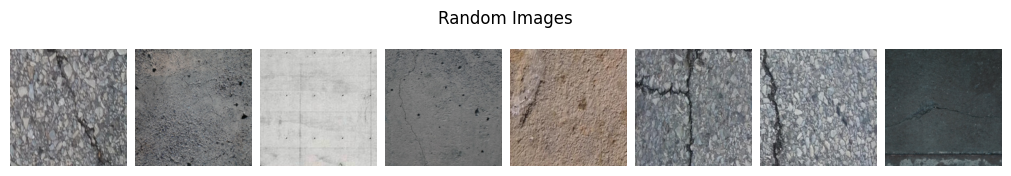

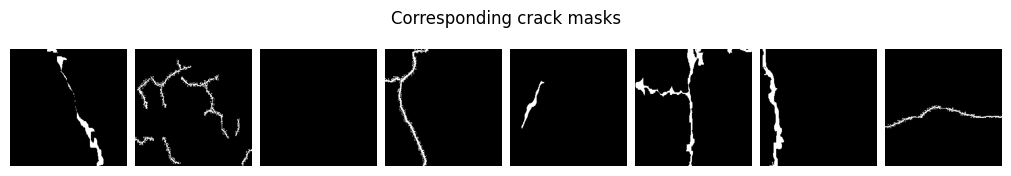

In [ ]:
# get 8 random indices
rand_indices = np.random.randint(0, len(train_dataset), 8)
# get samples
samples = [train_dataset[i] for i in rand_indices]

# images
f, axs = plt.subplots(1, 8, figsize=(10,4), layout='compressed')
f.suptitle('Random Images')
for (x, _), ax in zip(samples, axs):
  ax.imshow(x.permute(1,2,0))
  ax.axis(False)
plt.show()

# masks
f, axs = plt.subplots(1, 8, figsize=(10,4), layout='compressed')
f.suptitle('Corresponding crack masks')
for (_, y), ax in zip(samples, axs):
  ax.imshow(y.permute(1,2,0), cmap='gray')
  ax.axis(False)
plt.show()

#### Create [`DataLoaders`](https://docs.pytorch.org/docs/2.13/data.html#torch.utils.data.DataLoader)
Here, we shall create `DataLoaders` from the datasets previously defined

In [ ]:
# create datasets
# train
train_loader = DataLoader(
    dataset=train_dataset, batch_size=32, shuffle=True, drop_last=True,
    num_workers=os.cpu_count(), pin_memory=True
)

# validation
val_loader = DataLoader(
    dataset=val_dataset, batch_size=32, shuffle=False, drop_last=True,
    num_workers=os.cpu_count(), pin_memory=True
)

### Define the loss function

This is a binary segmentation task where the model is supposed to classify pixels as either 'background' or 'crack'
+ The industry standard to U-Net image segmentation is a combined loss of _BinaryCrossEntropy Loss_ and _Dice Loss_

📝 **Note**  
+ _Dice Loss_ can be calculated using the [`DiceLoss`](https://smp.readthedocs.io/en/latest/losses.html#diceloss) class from [`segmentation_models_pytorch`](https://smp.readthedocs.io/en/latest/models.html)
+ _BinaryCrossEntropy Loss_ can be calculated using [`nn.functional.binary_cross_entropy_with_logits`](https://docs.pytorch.org/docs/2.13/generated/torch.nn.functional.binary_cross_entropy_with_logits.html#torch-nn-functional-binary-cross-entropy-with-logits) from the [`torch`](https://pytorch.org/) library

In [ ]:
# import metrics from torchmetrics
from torchmetrics.segmentation import DiceScore, MeanIoU

In [ ]:
class BCEDiceLoss(nn.Module):
  def __init__(self, bce_weight=1.0, dice_weight=1.0):
    super().__init__()
    self.bce_weight = bce_weight
    self.dice_weight = dice_weight

    # initialize DiceScore object
    self.dice = smp.losses.DiceLoss(mode='binary')

  def forward(self, logits, targets):
    # 1. Calculate BCE loss from raw logits
    bce = F.binary_cross_entropy_with_logits(logits, targets)

    # 2. Calculate DiceLoss
    dice_loss = self.dice(logits, targets)

    return (self.dice_weight * dice_loss) + (self.bce_weight * bce)


### Set up Pytorch Lightning
> Pytorch lightning provides a high-level interface for PyTorch training and scaling

#### Add a [`LightningModule`](https://lightning.ai/docs/pytorch/stable/common/lightning_module.html)
The LightningModule is the full recipe that defines how your `nn.Modules` interact.
+ The [`training_step`](https://lightning.ai/docs/pytorch/stable/api/lightning.pytorch.core.LightningModule.html#lightning.pytorch.core.LightningModule.training_step) defines how the `nn.Module`(s) interact together.
+ In the [`configure_optimizers`](https://lightning.ai/docs/pytorch/stable/api/lightning.pytorch.core.LightningModule.html#lightning.pytorch.core.LightningModule.configure_optimizers) define the optimizer(s) for your models.

🔔 **Note**  
> Here, we'll also use a learning rate scheduler that incorporates a warm-up phase as well:  [`get_cosine_schedule_with_warmup`](https://huggingface.co/docs/transformers/main_classes/optimizer_schedules#transformers.get_cosine_schedule_with_warmup) - from Huggingface `transformers` package

In [ ]:
from transformers import get_cosine_schedule_with_warmup

In [ ]:
class LitModule(lightning.LightningModule):
  def __init__(self, model:smp.decoders.unet.model.Unet, num_classes=2):
    super().__init__()
    self.dice = DiceScore(num_classes=num_classes, include_background=True, input_format='index')
    self.miou = MeanIoU(num_classes=num_classes, include_background=True, input_format='index')
    self.bce_dice_loss = BCEDiceLoss()

    # freeze encoder for the first round of training
    self.model = model
    self.model.freeze_encoder()

  def forward(self, x):
    return self.model(x)

  def training_step(self, batch, batch_idx):
    x, y = batch
    # forward pass
    logits = self.model(x)
    loss = self.bce_dice_loss(logits, y)

    # log loss
    self.log(
        'train_loss', loss, prog_bar=True,
        on_step=False, on_epoch=True)

    return loss

  def validation_step(self, batch, batch_idx):
    x, y = batch

    # make prediction
    logits = self.model(x)

    # get predictions, targets class labels
    preds = (logits.sigmoid()>0.5).to(torch.int64)
    target = y.to(torch.int64)

    # update dice_score and mean_iou
    self.dice.update(preds, target)
    self.miou.update(preds, target)

    # log validation DiceScore & MeanIoU
    self.log_dict(
        {'val_dice':self.dice, 'val_miou':self.miou},
        prog_bar=True, on_step=False, on_epoch=True
    )

  def configure_optimizers(self):
    total_steps = self.trainer.estimated_stepping_batches

    # optimizer
    optimizer = optim.AdamW(params=self.model.parameters(), lr=1e-2)
    # lr scheduler
    scheduler = get_cosine_schedule_with_warmup(
        optimizer=optimizer,
        num_warmup_steps=(0.2*total_steps),
        num_training_steps=total_steps
    )

    return {
        'optimizer': optimizer,
        'lr_scheduler': {
            'scheduler': scheduler,
            'interval': 'step',
            'frequency': 1
        }
    }

#### Set up [`EarlyStopping`](https://lightning.ai/docs/pytorch/stable/api/lightning.pytorch.callbacks.EarlyStopping.html#earlystopping) and [`ModelCheckpoint`](https://lightning.ai/docs/pytorch/stable/api/lightning.pytorch.callbacks.ModelCheckpoint.html#modelcheckpoint)
+ `EarlyStopping` - Monitors a metric and stop training when it stops improving
+ `ModelCheckpoint` - Save the model after every epoch by monitoring a quantity

In [ ]:
# import
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint

# early stopping
early_stopping = EarlyStopping(
    monitor='train_loss',
    patience=3,
    min_delta=1e-5,
    mode='min'
)

# model checkpointing
model_checkpoint = ModelCheckpoint(
    dirpath=Path.cwd().joinpath('checkpoint'),
    monitor='train_loss',
    mode='min'
)

### Train the model
Once the PyTorch code has been organized in a `LightningModule`, the [`Trainer`](https://lightning.ai/docs/pytorch/stable/api/lightning.pytorch.trainer.trainer.Trainer.html) automates the core engineering and infrastructure details of training deep learning models
+ It also enables logging using `loggers` such as the [`CSVLogger`](https://lightning.ai/docs/pytorch/stable/extensions/generated/lightning.pytorch.loggers.CSVLogger.html#lightning.pytorch.loggers.CSVLogger)

In [ ]:
from lightning.pytorch.loggers import CSVLogger
from lightning.pytorch import Trainer

# path to save csv file
logger = CSVLogger(save_dir=Path.cwd().joinpath('logs'), name='training')

#### First training run
🔔 **Note**  
For the first training run:
+ The unet's `encoder` layer is frozen, hence, we're training the `decoder` and `segmentation_head`
+ We are using a larger learning rate on the optimizer, `1e-2`
+ We are training for 5 epochs

In [ ]:
# set up trainer object
trainer = Trainer(
    inference_mode=False,
    enable_model_summary=False,
    logger=logger,
    callbacks=[model_checkpoint, early_stopping],
    max_epochs=7,
    # limit_train_batches=0.4,
    # limit_val_batches=0.8,
)

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


In [ ]:
%%time
# train model
trainer.fit(
    model=LitModule(model=unet),
    train_dataloaders=train_loader,
    val_dataloaders=val_loader
)

INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: Loading `train_dataloader` to estimate number of stepping batches.
INFO:lightning.pytorch.utilities.rank_zero:Loading `train_dataloader` to estimate number of stepping batches.


Output()

INFO: `Trainer.fit` stopped: `max_epochs=7` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=7` reached.


CPU times: user 1min 28s, sys: 23.7 s, total: 1min 51s
Wall time: 10min 54s


In [ ]:
# !rm -rf /content/logs
# !rm -rf /content/checkpoint_01
# !rm -rf /content/checkpoint_02

In [ ]:
# !rm -rf /content/logs/training_01/version_2

##### **Load best model**

In [ ]:
unet = LitModule.load_from_checkpoint(
    model=unet,
    checkpoint_path='/content/epoch=6-step=2100.ckpt',
    map_location=device
)

unet = unet.model

##### **Save best model's `state_dict`**

In [ ]:
# save model weights & biases in root folder
torch.save(unet.state_dict(), Path.cwd().joinpath('crack_unet.pth'))

In [ ]:
# load
state_dict = torch.load(
    '/content/resnet18-unet.pth', device
)

unet.load_state_dict(state_dict)

<All keys matched successfully>

##### **Visualize training metrics**

In [ ]:
df = pd.read_csv('/content/logs/training/version_0/metrics.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   epoch       14 non-null     int64  
 1   step        14 non-null     int64  
 2   train_loss  7 non-null      float64
 3   val_dice    7 non-null      float64
 4   val_miou    7 non-null      float64
dtypes: float64(3), int64(2)
memory usage: 692.0 bytes


In [ ]:
df = df.groupby('epoch').first().reset_index()

# visualize DataFrame
df

,epoch,step,train_loss,val_dice,val_miou
0,0,299,0.681244,0.634383,0.576659
1,1,599,0.426409,0.618230,0.565584
2,2,899,0.380333,0.632779,0.577787
3,3,1199,0.356102,0.621673,0.570499
4,4,1499,0.335174,0.629050,0.576251
5,5,1799,0.313053,0.637936,0.580084
6,6,2099,0.298904,0.637031,0.580428


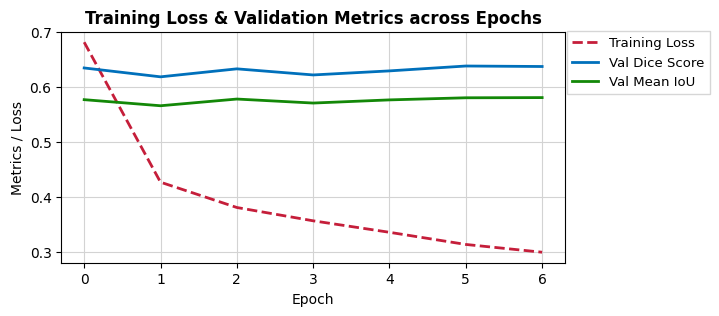

In [ ]:
# plot the metrics and loss
f, ax = plt.subplots(figsize=(6.5,3))
ax.set_title('Training Loss & Validation Metrics across Epochs', weight='black')
ax.set_ylabel('Metrics / Loss')
ax.set_xlabel('Epoch')
ax.plot(df['train_loss'], label='Training Loss', linewidth=2, color='#C51E3A', linestyle='--')
ax.plot(df['val_dice'], label='Val Dice Score', linewidth=2, color='#0070BB')
ax.plot(df['val_miou'], label='Val Mean IoU', linewidth=2, color='#138808')
ax.grid(color='lightgray')
plt.legend(fancybox=False, bbox_to_anchor=(1.3, 1.03), fontsize=9.5)
plt.show()

##### **Inference on `test_dataset`**

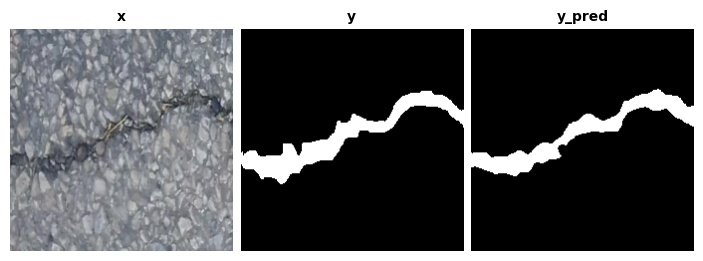

In [ ]:
# get random image from test dataset
x, y = test_dataset[np.random.randint(len(test_dataset))]

# perform inference
with torch.inference_mode():
  unet.eval(), unet.to(device)
  x = x.to(device)
  y_pred = unet(x.unsqueeze(dim=0))
  y_pred = (y_pred.sigmoid()>0.5).int()

# plot
f, axs = plt.subplots(1, 3, layout='compressed', figsize=(8,2.5))
axs[0].set_title('x', weight='black', fontsize=10)
axs[0].imshow(x.cpu().permute(1,2,0))
axs[0].axis(False)

axs[1].set_title('y', weight='black', fontsize=10)
axs[1].imshow(y.permute(1,2,0), cmap='gray')
axs[1].axis(False)

axs[2].set_title('y_pred', weight='black', fontsize=10)
axs[2].imshow(y_pred.cpu().squeeze(dim=0).permute(1,2,0), cmap='gray')
axs[2].axis(False)

plt.show()

##### **Inference on new Image**

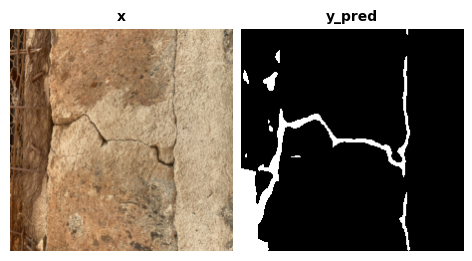

In [ ]:
transforms = T.Compose([
    T.ToImage(),
    T.ToDtype(dtype=torch.float32, scale=True),
    T.Resize((224,224)),
])
img = transforms(Image.open('/content/IMG_4455.JPG.jpeg'))

with torch.inference_mode():
  unet.eval(), unet.to(device)
  img = img.to(device)
  y_pred = unet(img.unsqueeze(dim=0))
  y_pred = (y_pred.sigmoid() > 0.5).to(torch.int64)

# plot
f, axs = plt.subplots(1, 2, layout='compressed', figsize=(8,2.5))
axs[0].set_title('x', weight='black', fontsize=10)
axs[0].imshow(img.cpu().permute(1,2,0))
axs[0].axis(False)

axs[1].set_title('y_pred', weight='black', fontsize=10)
axs[1].imshow(y_pred.cpu().squeeze(dim=0).permute(1,2,0), cmap='gray')
axs[1].axis(False)

plt.show()

# Coding [`gradio`](https://gradio.app/) interface
> This will run in the current Jupyter Notebook

In [ ]:
# install smp
!pip install -qU git+https://github.com/qubvel/segmentation_models.pytorch

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import torch
import segmentation_models_pytorch as smp
import gradio as gr
import numpy as np
import torchvision.transforms.v2 as T
from huggingface_hub import hf_hub_download
import PIL
from google.colab import userdata

In [ ]:
from google.colab import userdata

# save HF token in .env file
with Path.cwd().joinpath('.env').open(mode='w') as f:
  f.write(f'HF_TOKEN={userdata.get('HF_TOKEN')}')

In [ ]:
"""
______________________________
DELETE FOR HUGGINGFACE SPACES
______________________________
"""
if torch.cuda.is_available():
  device = 'cuda'
elif torch.backends.mps.is_available():
  device = 'mps'
else:
  device = 'cpu'

transforms = T.Compose([
    T.ToImage(),
    T.ToDtype(dtype=torch.float32, scale=True),
    T.Resize((224,224))
])

# download weights
weights_path = hf_hub_download(
    repo_id='martinmbiro/resnet18-unet-crack-segmentation',
    filename='resnet18-unet.pth',
    token=userdata.get('HF_TOKEN')
)

# load weights
state_dict = torch.load(
    f=weights_path,
    map_location=device
)

# initialize unet with resnet50 encoder backbone
model = smp.Unet(
    encoder_name='resnet18',    # resnet18 backbone
    encoder_weights='imagenet', # with pre-trained weights
    in_channels=3,              # for RGB images
    classes=1                   # 1 output channel for crack probability
)

resnet18-unet.pth: reconstructing file:   0%|          |  0.00B / 57.4MB            

resnet18-unet.pth: downloading bytes:           |  0.00B            

##### Load `state_dict`

In [ ]:
# load_state_dict, move model to device, eval
model.load_state_dict(state_dict)
model.to(device)
model.eval();

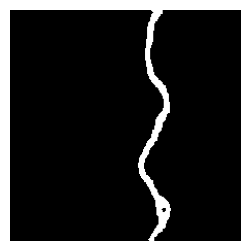

In [ ]:
img = Image.open('/content/Volker_DSC01636_1084_9_1476_1810.jpg')
# transform, unsqueeze, move to device
img = transforms(img).unsqueeze(0).to(device)

mask = (model(img).sigmoid() > 0.5).to(torch.int64)
mask = mask.squeeze((0,1)).cpu().numpy()

f, ax = plt.subplots(figsize=(3,3))
ax.imshow(mask, cmap='gray')
ax.axis(False)
plt.show()

#### `gradio` UI interface

In [ ]:
# function to run on submit
def generate(img: PIL.Image):
  if img:
    # Transform
    img = transforms(img).unsqueeze(0).to(device)

    # Inference
    mask = (model(img).sigmoid() > 0.5).to(torch.int64)

    # Tensor -> NumPy
    mask = mask.squeeze((0, 1)).cpu().numpy()

    # 0/1 -> 0/255
    mask = (mask * 255).astype("uint8")

    return mask

  else:
    gr.Info(
        message="Upload an Image or choose from the samples",
        duration=4
    )
    return None

example_list = [
    '/content/noncrack_noncrack_concrete_wall_41_58.jpg.jpg',
    '/content/CRACK500_20160308_160128_641_361.jpg',
    '/content/WhatsApp Image 2026-09-23 at 1.39.27 PM.jpeg',
    '/content/Volker_DSC01636_1084_9_1476_1810.jpg'
]

custom_css = """
  #txt {
    text-align: center;
  }

  #submit_btn {
    background: #FADA5E !important;
    font-weight: normal !important;
    color: #000000 !important;
  }

  #clear_btn {
    font-weight: normal !important;
  }
"""

with gr.Blocks() as demo:
  # title and message
  gr.Markdown(
    """
      ## U-NET Crack Segmentation
      > _This Web App runs a U-Net model to perform crack segmentation. **Black** pixels indicate no crack. **White** pixels show where the cracks appear_


    """, elem_id='txt')

  # input & output image row
  with gr.Row():
    input_img = gr.Image(
        type='pil', label='input', sources='upload',
        height=224, width=224, interactive=True, scale=1)

    output_img = gr.Image(
        label='mask', interactive=False, height=224, width=224, scale=1)

  # button row
  with gr.Row():
    with gr.Row(scale=1):
      submit_btn = gr.Button('✔️ Submit', variant='primary', size='md', elem_id='submit_btn')
      gr.ClearButton([input_img, output_img], value='🗑️ Clear', size='md', elem_id='clear_btn')
    with gr.Column(scale=1):
      pass

  # image examples
  with gr.Row():
    gr.Examples(
        fn=generate,
        run_on_click=True,
        examples=example_list,
        inputs=input_img,
        outputs=output_img,
        label='Try these samples:',
        cache_examples=True,
        cache_mode='lazy',
        preload=False,
    )

    with gr.Column(scale=2):
      pass

  # footer
  gr.Markdown(
      """
      _Find github repository and documentation linked [here](https://github.com/Martinmbiro/unet-crack-segmentation)_<br>
      """,
      elem_id='txt'
  )

  submit_btn.click(
      fn=generate,
      inputs= input_img,
      outputs= output_img
  )

demo.queue().launch(css=custom_css, share=True)#, theme=gr.themes.Soft(), debug=True)

Will cache examples in '/content/.gradio/cached_examples/11' directory at first use.

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f75026c4b85a3b1f5a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


# Turn code into python modules
Here, we'll organize the most relevant bits of code into `.py` files that can be executed if hosted (say on [Huggingface Spaces](https://huggingface.co/spaces)

In [ ]:
# install smp
!pip install -qU git+https://github.com/qubvel/segmentation_models.pytorch

In [ ]:
"""
THIS IS PURELY FOR TESTING ON COLAB
"""
from google.colab import userdata
from pathlib import Path
import shutil

# save HF token in .env file
with Path.cwd().joinpath('.env').open(mode='w') as f:
  f.write(f'HF_TOKEN={userdata.get('HF_TOKEN')}')

In [ ]:
"""
THIS IS PURELY FOR TESTING ON COLAB
"""
# make new folder named 'examples'
examples = Path.cwd().joinpath('examples')
examples.mkdir(parents=True, exist_ok=True)

# get .jpg images in current working directory
images = Path.cwd().rglob('*.jpg')

# move all those images to the new folder
for image in images:
  shutil.move(src=image, dst=examples)

#### Model loading

In [ ]:
%%writefile model_loader.py
import torch
import os
from pathlib import Path
import torchvision.transforms.v2 as T
from huggingface_hub import hf_hub_download
import segmentation_models_pytorch as smp
"""
______________________________
DELETE FOR HUGGINGFACE SPACES
______________________________
"""
from dotenv import load_dotenv, find_dotenv
load_dotenv(find_dotenv())

# get list of example photos
BASE_PATH = Path(__file__).resolve().parent
example_list = list(BASE_PATH.joinpath('examples').rglob('*.jpg'))

# check available device
if torch.cuda.is_available():
  device = 'cuda'
elif torch.backends.mps.is_available():
  device = 'mps'
else:
  device = 'cpu'

transforms = T.Compose([
    T.ToImage(),
    T.ToDtype(dtype=torch.float32, scale=True),
    T.Resize((224,224))
])

def load_model() -> torch.nn.Module:
  """Downloads fine-tuned weights from Hugging Face Hub and initializes the segmentation model.

    Returns
    -------
    torch.nn.Module
        A Segmentation Models PyTorch (smp) U-Net model with a ResNet-18 backbone,
        loaded with fine-tuned weights and set to evaluation mode on the target device.
  """
  # download weights
  weights_path = hf_hub_download(
    repo_id='martinmbiro/resnet18-unet-crack-segmentation',
    filename='resnet18-unet.pth',
    token=os.environ.get('HF_TOKEN')
  )

  # load weights
  state_dict = torch.load(f=weights_path, map_location=device)

  # initialize unet with resnet18 encoder backbone
  model = smp.Unet(
      encoder_name='resnet18',    # resnet18 backbone
      encoder_weights='imagenet', # with pre-trained weights
      in_channels=3,              # for RGB images
      classes=1                   # 1 output channel for crack probability
  )

  # load_state_dict, move model to device, set model to eval mode
  model.load_state_dict(state_dict)
  model.to(device)
  model.eval()

  return model

model = load_model()

Writing model_loader.py


#### Gradio UI App & Inference code





In [ ]:
%%writefile app.py
import spaces
import torch
from model_loader import model, device, transforms, example_list
import gradio as gr
import PIL
import numpy as np

# function to perform inference
def generate(model: torch.nn.Module, img: torch.Tensor) -> torch.Tensor:
  """Performs Inference on an input image tensor.

    Parameters
    ----------
    model : torch.nn.Module
        The loaded U-Net segmentation model.
    img : torch.Tensor
        A preprocessed 4D image tensor of shape (1, C, H, W) on the target device.

    Returns
    -------
    torch.Tensor
        Raw output logits tensor from the model.
  """
  with torch.inference_mode():
    logits = model(img)

  return logits

# function to run once submit is clicked
def on_click(img: PIL.Image.Image | None) -> np.ndarray | None:
  """Handles the UI submit event by preprocessing the image, running inference, and generating a binary mask.

    Parameters
    ----------
    img : PIL.Image.Image or None
        Input RGB image provided by the user via the UI.

    Returns
    -------
    np.ndarray or None
        A 2D uint8 NumPy array of shape (H, W) with pixel values 0 or 255 representing
        the predicted crack mask, or None if no image was provided.
  """
  if img:
    # Transform
    img = transforms(img).unsqueeze(0).to(device)

    # Inference
    logits = generate(model, img)

    # predicted mask:
    mask = (logits.sigmoid() > 0.5).to(torch.int64)

    # Tensor -> NumPy
    mask = mask.squeeze((0, 1)).cpu().numpy()

    # 0/1 -> 0/255
    mask = (mask * 255).astype("uint8")

    return mask

  else:
    gr.Info(
        message="Upload an Image or choose from the samples",
        duration=4
    )
    return None

custom_css = """
  #txt {
    text-align: center;
  }

  #submit_btn {
    background: #FADA5E !important;
    font-weight: normal !important;
    color: #000000 !important;
  }

  #clear_btn {
    font-weight: normal !important;
  }

"""

with gr.Blocks() as demo:
  # title and message
  gr.Markdown(
    """
      ## U-NET Crack Segmentation
      > _This Web App runs a U-Net model to perform crack segmentation. **Black** pixels indicate no crack. **White** pixels show where the cracks appear_


    """, elem_id='txt')

  # input & output image row
  with gr.Row():
    input_img = gr.Image(
        type='pil', label='input', sources='upload',
        height=224, width=224, interactive=True, scale=1)

    output_img = gr.Image(
        label='mask', interactive=False, height=224, width=224, scale=1)

  # button row
  with gr.Row():
    with gr.Row(scale=1):
      submit_btn = gr.Button('✔️ Submit', variant='primary', size='md', elem_id='submit_btn')
      gr.ClearButton([input_img, output_img], value='🗑️ Clear', size='md', elem_id='clear_btn')
    with gr.Column(scale=1):
      pass

  # image examples
  with gr.Row():
    gr.Examples(
        fn=on_click,
        run_on_click=True,
        examples=example_list,
        inputs=input_img,
        outputs=output_img,
        label='Try these samples:',
        cache_examples=True,
        cache_mode='lazy',
        preload=False,
    )

    with gr.Column(scale=2):
      pass

  # footer
  gr.Markdown(
      """
      _Find GitHub repository and documentation linked [here](https://github.com/Martinmbiro/unet-crack-segmentation)_<br>
      """,
      elem_id='txt'
  )

  submit_btn.click(
      fn=on_click,
      inputs= input_img,
      outputs= output_img
  )

demo.queue().launch(css=custom_css, share=True)#, theme=gr.themes.Soft(), debug=True)

Writing app.py


# [ZeroGPU](https://huggingface.co/docs/hub/spaces-zerogpu?utm_source=chatgpt.com) compatible Python modules
To host our Web App on Huggingface Spaces for free, we have to make sure that the Python modules we just extracted are [ZeroGPU](https://huggingface.co/docs/hub/spaces-zerogpu?utm_source=chatgpt.com) compatible  


#### Model loading
Here, we instantiate the model and load its pre-trained weights without moving it to any device

In [ ]:
%%writefile model_loader.py
import torch
import os
from pathlib import Path
import torchvision.transforms.v2 as T
from huggingface_hub import hf_hub_download
import segmentation_models_pytorch as smp

# get list of example photos
BASE_PATH = Path(__file__).resolve().parent
example_list = list(BASE_PATH.joinpath('examples').rglob('*.jpg'))

transforms = T.Compose([
    T.ToImage(),
    T.ToDtype(dtype=torch.float32, scale=True),
    T.Resize((224,224))
])

def load_model() -> torch.nn.Module:
  """Downloads fine-tuned weights from Hugging Face Hub and initializes the segmentation model.

    Returns
    -------
    torch.nn.Module
        A Segmentation Models PyTorch (smp) U-Net model with a ResNet-18 backbone,
        loaded with fine-tuned weights and set to evaluation mode on the target device.
  """
  # download weights
  weights_path = hf_hub_download(
    repo_id='martinmbiro/resnet18-unet-crack-segmentation',
    filename='resnet18-unet.pth',
    token=os.environ.get('HF_TOKEN')
  )

  # load weights
  state_dict = torch.load(f=weights_path, map_location='cpu')

  # initialize unet with resnet18 encoder backbone
  model = smp.Unet(
      encoder_name='resnet18',    # resnet18 backbone
      encoder_weights='imagenet', # with pre-trained weights
      in_channels=3,              # for RGB images
      classes=1                   # 1 output channel for crack probability
  )

  # load_state_dict, set model to eval mode
  model.load_state_dict(state_dict)
  model.eval()

  return model

model = load_model()

Overwriting model_loader.py


#### Gradio UI App & Inference code
📝 **Note**  
+ [ZeroGPU](https://huggingface.co/docs/hub/spaces-zerogpu?utm_source=chatgpt.com) generally expects GPU-dependent work to run inside a function decorated with `@spaces.GPU`
+ The models must be placed on `cuda` at the root module level
+ Lazy-loading or moving models to CUDA inside` @spaces.GPU` is discouraged, as it is significantly less efficient
> _This is according to the official [ZeroGPU guide](https://huggingface.co/docs/hub/spaces-zerogpu?utm_source=chatgpt.com)_

In [ ]:
%%writefile app.py
import spaces
import torch
from model_loader import model, transforms, example_list
import gradio as gr
import PIL
import numpy as np

# move model to cuda at module level
model.to('cuda')

# function to perform inference
@spaces.GPU
def generate(img: torch.Tensor) -> torch.Tensor:
  """Performs GPU-accelerated forward pass inference on an input image tensor.

    Parameters
    ----------
    img : torch.Tensor
        A preprocessed 4D image tensor of shape (1, C, H, W)

    Returns
    -------
    torch.Tensor
        Raw output logits tensor from the model.
  """
  # This function runs in the ZeroGPU worker
  img = img.to('cuda')

  with torch.inference_mode():
    logits = model(img)

  # Return a CPU tensor across the worker boundary
  return logits.cpu()

# function to run once submit is clicked
def on_click(img: PIL.Image.Image | None) -> np.ndarray | None:
  """Handles the UI submit event by preprocessing the image, running inference, and generating a binary mask.

    Parameters
    ----------
    img : PIL.Image.Image or None
        Input RGB image provided by the user via the UI.

    Returns
    -------
    np.ndarray or None
        A 2D uint8 NumPy array of shape (H, W) with pixel values 0 or 255 representing
        the predicted crack mask, or None if no image was provided.
  """
  if img:
    # Transform
    img = transforms(img).unsqueeze(0)

    # GPU inference happens inside the decorated function
    logits = generate(img)

    # predicted mask:
    mask = (logits.sigmoid() > 0.5).to(torch.int64)

    # Tensor -> NumPy
    mask = mask.squeeze((0, 1)).numpy()
    # 0/1 -> 0/255
    mask = (mask * 255).astype("uint8")

    return mask

  else:
    gr.Info(
        message="Upload an Image or choose from the samples",
        duration=4
    )
    return None

custom_css = """
  #txt {
    text-align: center;
  }

  #submit_btn {
    background: #FADA5E !important;
    font-weight: normal !important;
    color: #000000 !important;
  }

  #clear_btn {
    font-weight: normal !important;
  }

"""

with gr.Blocks() as demo:
  # title and message
  gr.Markdown(
    """
      ## U-NET Crack Segmentation
      > _This Web App runs a U-Net model to perform crack segmentation. **Black** pixels indicate no crack. **White** pixels show where the cracks appear_


    """, elem_id='txt')

  # input & output image row
  with gr.Row():
    input_img = gr.Image(
        type='pil', label='input', sources='upload',
        height=224, width=224, interactive=True, scale=1)

    output_img = gr.Image(
        label='mask', interactive=False, height=224, width=224, scale=1)

  # button row
  with gr.Row():
    with gr.Row(scale=1):
      submit_btn = gr.Button('✔️ Submit', variant='primary', size='md', elem_id='submit_btn')
      gr.ClearButton([input_img, output_img], value='🗑️ Clear', size='md', elem_id='clear_btn')
    with gr.Column(scale=1):
      pass

  # image examples
  with gr.Row():
    gr.Examples(
        fn=on_click,
        run_on_click=True,
        examples=example_list,
        inputs=input_img,
        outputs=output_img,
        label='Try these samples:',
        cache_examples=True,
        cache_mode='lazy',
        preload=False,
    )

    with gr.Column(scale=2):
      pass

  # footer
  gr.Markdown(
      """
      _Find GitHub repository and documentation linked [here](https://github.com/Martinmbiro/unet-crack-segmentation)_<br>
      """,
      elem_id='txt'
  )

  submit_btn.click(
      fn=on_click,
      inputs= input_img,
      outputs= output_img
  )

demo.queue().launch(css=custom_css)

Overwriting app.py


#### `requirements.txt`
This is a list of Python dependencies that Huggingface Space installs

In [ ]:
from pathlib import Path

with Path.cwd().joinpath('requirements.txt').open(mode='w') as f:
  f.write('torch\n')
  f.write('segmentation-models-pytorch\n')
  f.write('numpy\n')
  f.write('torchvision\n')
  f.write('Pillow')

#### `README.md`
This is Hugging Face Space configuration and description
+ This should be saved as `README.md`
```
    ---
    title: Crack Segmentation
    emoji: 💔
    colorFrom: indigo
    colorTo: gray
    sdk: gradio
    sdk_version: "6.29.0"
    app_file: app.py
    pinned: false
    ---
```

#### `examples` 📂
We shall also include an `examples` directory with sample images that the user can click on to test our model. All the files & directories in this section will be included in our Space repository  

📝 **Note**  
+ See the `space` directory of this repository
+ Refer to `README.md` for this repository